In [1]:
import tensorflow as tf
import keras

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.13.2
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
%pip install -q tf-keras

In [3]:
import os

os.environ["TF_USE_LEGACY_KERAS"] = "1"

import tensorflow as tf
import tf_keras as keras

print("TensorFlow:", tf.__version__)
print("Legacy Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Legacy Keras: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
%pip uninstall -y transformers

Found existing installation: transformers 5.22.1
Uninstalling transformers-5.22.1:
  Successfully uninstalled transformers-5.22.1


In [5]:
%pip install --no-cache-dir "transformers==4.57.6"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 32.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 430.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 84.4 MB/s  0:00:00
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.0
  Attempting uninstall: tokenizers
    Found existing installation: tokenizers 0.23.3
    Uninstalling tokenizers-0.23.3:
      Successfully uninstalled tokenizers-0.23.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [transformers]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but

In [6]:
import os
os.environ["TF_USE_LEGACY_KERAS"] = "1"

import transformers

print(transformers.__version__)
print(transformers.__file__)

4.57.6
/usr/local/lib/python3.13/dist-packages/transformers/__init__.py


In [7]:
%pip install --no-cache-dir --force-reinstall --no-deps "transformers==4.57.6"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 34.1 MB/s  0:00:00
  Attempting uninstall: transformers
    Found existing installation: transformers 4.57.6
    Uninstalling transformers-4.57.6:
      Successfully uninstalled transformers-4.57.6


In [8]:
import os
import tensorflow as tf
import tf_keras
import transformers

print("TF_USE_LEGACY_KERAS:", os.environ.get("TF_USE_LEGACY_KERAS"))
print("TensorFlow:", tf.__version__)
print("Legacy Keras:", tf_keras.__version__)
print("Transformers:", transformers.__version__)
print("TensorFlow available:", transformers.is_tf_available())

TF_USE_LEGACY_KERAS: 1
TensorFlow: 2.21.0
Legacy Keras: 2.21.0
Transformers: 4.57.6
TensorFlow available: True


In [9]:
from transformers import BertTokenizer, TFBertModel


In [10]:
base_model="bert-base-uncased"

In [11]:
tokenizer=BertTokenizer.from_pretrained(base_model)
bert=TFBertModel.from_pretrained(base_model,use_safetensors=False)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tf_model.h5:   0%|          | 0.00/536M [00:00<?, ?B/s]

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.
Some layers from the model checkpoint at bert-base-uncased were not used when initializing TFBertModel: ['nsp___cls', 'mlm___cls']
- This IS expected if you are initializing TFBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFBertModel were initialized from the model checkpoint at bert-base-uncased.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions without further training

In [12]:
print(bert)

In [13]:
print("Number of encoder layers:",
      len(bert.bert.encoder.layer))

print("Hidden size:",
      bert.config.hidden_size)

print("Number of attention heads:",
      bert.config.num_attention_heads)

print("Vocabulary size:",
      bert.config.vocab_size)

Number of encoder layers: 12
Hidden size: 768
Number of attention heads: 12
Vocabulary size: 30522


In [14]:
text = "This movie was absolutely amazing!"

inputs = tokenizer(
    text,
    return_tensors="tf"
)

print(inputs)

TensorFlow and JAX classes are deprecated and will be removed in Transformers v5. We recommend migrating to PyTorch classes or pinning your version of Transformers.


{'input_ids': <tf.Tensor: shape=(1, 8), dtype=int32, numpy=array([[ 101, 2023, 3185, 2001, 7078, 6429,  999,  102]], dtype=int32)>, 'token_type_ids': <tf.Tensor: shape=(1, 8), dtype=int32, numpy=array([[0, 0, 0, 0, 0, 0, 0, 0]], dtype=int32)>, 'attention_mask': <tf.Tensor: shape=(1, 8), dtype=int32, numpy=array([[1, 1, 1, 1, 1, 1, 1, 1]], dtype=int32)>}


In [15]:
for key, value in inputs.items():
    print(key, value.shape)

input_ids (1, 8)
token_type_ids (1, 8)
attention_mask (1, 8)


In [16]:
outputs = bert(**inputs)

print(outputs)

TFBaseModelOutputWithPoolingAndCrossAttentions(last_hidden_state=<tf.Tensor: shape=(1, 8, 768), dtype=float32, numpy=
array([[[ 0.20666577,  0.02617075,  0.09247515, ..., -0.34793714,
          0.23239616,  0.04280992],
        [-0.6449769 , -0.4758043 ,  0.14977226, ..., -0.63938665,
          0.6062592 ,  0.06590503],
        [ 0.32343167, -0.41544783,  0.02279544, ..., -0.4127666 ,
          0.05623129, -0.19015987],
        ...,
        [ 0.23819806,  0.10146501,  0.09097277, ..., -0.6192268 ,
          0.6100487 , -0.7651363 ],
        [ 0.10400308, -0.47748464, -0.23184761, ...,  0.6612995 ,
          0.56259227, -0.53112376],
        [ 0.6879222 ,  0.04697267, -0.09903015, ..., -0.05640122,
         -0.63476795, -0.2395419 ]]], shape=(1, 8, 768), dtype=float32)>, pooler_output=<tf.Tensor: shape=(1, 768), dtype=float32, numpy=
array([[-9.01511252e-01, -3.77781153e-01, -5.56619704e-01,
         6.12410426e-01,  4.86352354e-01, -1.56622604e-01,
         8.52842152e-01,  2.34181270e

In [17]:
print("Last hidden state:", outputs.last_hidden_state.shape)
print("Pooled output:", outputs.pooler_output.shape)

Last hidden state: (1, 8, 768)
Pooled output: (1, 768)


In [18]:
import tf_keras as keras

# Extract the final CLS representation
cls_vector = outputs.last_hidden_state[:, 0, :]

# Our own classification layers
x = keras.layers.Dropout(0.3)(cls_vector)

output = keras.layers.Dense(
    2,
    activation="softmax"
)(x)

In [19]:
first_layer=bert.bert.encoder.layer[0]
first_layer

In [20]:
first_layer.attention

In [21]:
first_layer.intermediate

In [22]:
first_layer.bert_output

In [23]:
self_attention = first_layer.attention.self_attention

print(type(self_attention))
print(self_attention)

<class 'transformers.models.bert.modeling_tf_bert.TFBertSelfAttention'>


In [24]:
for weight in self_attention.weights:
    print("Name:", weight.name)
    print("Shape:", weight.shape)
    print("-" * 40)

Name: tf_bert_model/bert/encoder/layer_._0/attention/self/query/kernel:0
Shape: (768, 768)
----------------------------------------
Name: tf_bert_model/bert/encoder/layer_._0/attention/self/query/bias:0
Shape: (768,)
----------------------------------------
Name: tf_bert_model/bert/encoder/layer_._0/attention/self/key/kernel:0
Shape: (768, 768)
----------------------------------------
Name: tf_bert_model/bert/encoder/layer_._0/attention/self/key/bias:0
Shape: (768,)
----------------------------------------
Name: tf_bert_model/bert/encoder/layer_._0/attention/self/value/kernel:0
Shape: (768, 768)
----------------------------------------
Name: tf_bert_model/bert/encoder/layer_._0/attention/self/value/bias:0
Shape: (768,)
----------------------------------------


In [25]:
embeddings = bert.bert.embeddings(
    input_ids=inputs["input_ids"],
    token_type_ids=inputs["token_type_ids"]
)

print("Embeddings shape:", embeddings.shape)

Embeddings shape: (1, 8, 768)


In [26]:
query = self_attention.query(embeddings)
key = self_attention.key(embeddings)
value = self_attention.value(embeddings)

print("Query shape:", query.shape)
print("Key shape:", key.shape)
print("Value shape:", value.shape)

Query shape: (1, 8, 768)
Key shape: (1, 8, 768)
Value shape: (1, 8, 768)


In [27]:
batch_size = query.shape[0]
sequence_length = query.shape[1]
num_heads = bert.config.num_attention_heads
head_dim = bert.config.hidden_size // num_heads

query_reshaped = tf.reshape(
    query,
    (batch_size, sequence_length, num_heads, head_dim)
)

print("Before transpose:", query_reshaped.shape)

Before transpose: (1, 8, 12, 64)


In [28]:
query_transposed = tf.transpose(
    query_reshaped,
    perm=[0, 2, 1, 3]
)

print("After transpose:", query_transposed.shape)

After transpose: (1, 12, 8, 64)


In [29]:
key_reshaped = tf.reshape(
    key, (batch_size, sequence_length, num_heads, head_dim)
)

key_transposed = tf.transpose(
    key_reshaped, perm=[0, 2, 1, 3]
)

value_reshaped = tf.reshape(
    value, (batch_size, sequence_length, num_heads, head_dim)
)

value_transposed = tf.transpose(
    value_reshaped, perm=[0, 2, 1, 3]
)

print("Query:", query_transposed.shape)
print("Key:", key_transposed.shape)
print("Value:", value_transposed.shape)

Query: (1, 12, 8, 64)
Key: (1, 12, 8, 64)
Value: (1, 12, 8, 64)


In [30]:
key_transposed_for_scores = tf.transpose(
    key_transposed,
    perm=[0, 1, 3, 2]
)

attention_scores = tf.matmul(
    query_transposed,
    key_transposed_for_scores
)

print("Attention scores shape:", attention_scores.shape)

Attention scores shape: (1, 12, 8, 8)


In [31]:
import tensorflow as tf

scaled_attention_scores = attention_scores / tf.math.sqrt(
    tf.cast(head_dim, tf.float32)
)

print("Scaled attention scores shape:",
      scaled_attention_scores.shape)

Scaled attention scores shape: (1, 12, 8, 8)


In [32]:
attention_weights = tf.nn.softmax(
    scaled_attention_scores,
    axis=-1
)

print("Attention weights shape:", attention_weights.shape)

Attention weights shape: (1, 12, 8, 8)


In [33]:
print(attention_weights[0, 1].numpy())

[[0.931696   0.01043619 0.0074378  0.01713369 0.00785601 0.00468964
  0.01240733 0.00834324]
 [0.00578563 0.00985657 0.07983279 0.03603638 0.44213393 0.34948224
  0.04980139 0.02707105]
 [0.03740487 0.01216705 0.19132559 0.02174861 0.22423814 0.31871536
  0.05545755 0.13894281]
 [0.00409045 0.01320829 0.23101516 0.0247157  0.2698872  0.37691396
  0.05525938 0.02490983]
 [0.03058679 0.02160034 0.5190971  0.01422788 0.04998554 0.24998274
  0.07052701 0.04399261]
 [0.02342771 0.02821198 0.17830217 0.01781495 0.18089414 0.26896805
  0.13437313 0.16800787]
 [0.02042299 0.06349009 0.11403341 0.03997457 0.20233744 0.33686703
  0.18658966 0.03628471]
 [0.05622476 0.30789822 0.05043991 0.21284993 0.04076493 0.03467424
  0.24040663 0.05674136]]


In [34]:
row_sums = tf.reduce_sum(attention_weights, axis=-1)

print(row_sums[0, 1].numpy())

[0.9999999  1.         1.         1.         1.         1.
 0.99999994 0.99999994]


In [35]:
attention_output = tf.matmul(
    attention_weights,
    value_transposed
)

print("Attention output shape:", attention_output.shape)

Attention output shape: (1, 12, 8, 64)


In [36]:
attention_output = tf.transpose(
    attention_output,
    perm=[0, 2, 1, 3]
)

print(attention_output.shape)

(1, 8, 12, 64)


In [37]:
attention_output = tf.reshape(
    attention_output,
    (batch_size, sequence_length, num_heads * head_dim)
)

print("Final shape:", attention_output.shape)

Final shape: (1, 8, 768)


In [38]:
attention = first_layer.attention
self_attention = attention.self_attention

In [39]:
first_layer = bert.bert.encoder.layer[0]
attention = first_layer.attention

In [40]:
!pip install importlib_resources

In [41]:
!pip install -q datasets

In [42]:
from datasets import load_dataset

imdb = load_dataset("imdb")

print(imdb)

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 25000
    })
    unsupervised: Dataset({
        features: ['text', 'label'],
        num_rows: 50000
    })
})


In [43]:

# FAST PIPELINE: 10K train + 2.5K test

import numpy as np
import tensorflow as tf

MAX_LENGTH = 128
BATCH_SIZE = 16

# Reuse the original IMDb datasets
train_subset = imdb["train"].select(range(10000))
test_subset = imdb["test"].select(range(2500))

# Batch tokenization
def tokenize_fast(dataset):
    encoded = tokenizer(
        list(dataset["text"]),
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="np"
    )

    features = {
        "input_ids": encoded["input_ids"].astype(np.int32),
        "attention_mask": encoded["attention_mask"].astype(np.int32),
        "token_type_ids": encoded["token_type_ids"].astype(np.int32)
    }

    labels = np.array(dataset["label"], dtype=np.int32)

    return features, labels


train_features, train_labels = tokenize_fast(train_subset)
test_features, test_labels = tokenize_fast(test_subset)

# TensorFlow datasets
train_dataset = tf.data.Dataset.from_tensor_slices(
    (train_features, train_labels)
).shuffle(10000, seed=42).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (test_features, test_labels)
).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print("Training:", train_features["input_ids"].shape)
print("Testing:", test_features["input_ids"].shape)
print("Preprocessing complete!")


Training: (10000, 128)
Testing: (2500, 128)
Preprocessing complete!


In [44]:

import tensorflow as tf
import tf_keras as keras
from transformers import TFBertModel

# ==========================================
# 1. Configuration
# ==========================================

MODEL_NAME = "bert-base-uncased"
LEARNING_RATE = 2e-5

# ==========================================
# 2. Load pretrained BERT
# ==========================================

bert = TFBertModel.from_pretrained(
    MODEL_NAME,
    use_safetensors=False
)

# ==========================================
# 3. Define model inputs
# ==========================================

input_ids = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="input_ids"
)

attention_mask = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="attention_mask"
)

token_type_ids = keras.Input(
    shape=(MAX_LENGTH,),
    dtype=tf.int32,
    name="token_type_ids"
)

# ==========================================
# 4. Pass inputs through BERT
# ==========================================

bert_outputs = bert(
    input_ids=input_ids,
    attention_mask=attention_mask,
    token_type_ids=token_type_ids
)

# Extract CLS representation
cls_vector = bert_outputs.last_hidden_state[:, 0, :]

# ==========================================
# 5. Custom classification head
# ==========================================

x = keras.layers.Dropout(0.3)(cls_vector)

output = keras.layers.Dense(
    2,
    activation="softmax",
    name="sentiment_output"
)(x)

# ==========================================
# 6. Create model
# ==========================================

model = keras.Model(
    inputs={
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "token_type_ids": token_type_ids
    },
    outputs=output
)

# ==========================================
# 7. Compile model
# ==========================================

model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=LEARNING_RATE
    ),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

# ==========================================
# 8. Display model
# ==========================================

model.summary()

print("\nTotal parameters:", model.count_params())
print("BERT trainable:", bert.trainable)


Some layers from the model checkpoint at bert-base-uncased were not used when initializing TFBertModel: ['nsp___cls', 'mlm___cls']
- This IS expected if you are initializing TFBertModel from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing TFBertModel from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
All the layers of TFBertModel were initialized from the model checkpoint at bert-base-uncased.
If your task is similar to the task the model of the checkpoint was trained on, you can already use TFBertModel for predictions without further training.


Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_ids (InputLayer)      [(None, 128)]                0         []                            
                                                                                                  
 attention_mask (InputLayer  [(None, 128)]                0         []                            
 )                                                                                                
                                                                                                  
 token_type_ids (InputLayer  [(None, 128)]                0         []                            
 )                                                                                                
                                                                                              

In [52]:
import numpy as np
from sklearn.model_selection import train_test_split

SEED = 42

# Original IMDb training data
original_train = imdb["train"]

# Separate negative and positive examples
negative_indices = np.where(
    np.array(original_train["label"]) == 0
)[0]

positive_indices = np.where(
    np.array(original_train["label"]) == 1
)[0]

rng = np.random.default_rng(SEED)

# Select 5,000 examples from each class
negative_indices = rng.choice(negative_indices, 5000, replace=False)
positive_indices = rng.choice(positive_indices, 5000, replace=False)

selected_indices = np.concatenate([
    negative_indices,
    positive_indices
])

rng.shuffle(selected_indices)

# Select reviews and labels
texts = np.array(original_train["text"])[selected_indices]
labels = np.array(original_train["label"])[selected_indices]

# Split into training and validation
train_texts, val_texts, train_labels, val_labels = train_test_split(
    texts,
    labels,
    test_size=1000,
    random_state=SEED,
    stratify=labels
)

print("Training:", np.unique(train_labels, return_counts=True))
print("Validation:", np.unique(val_labels, return_counts=True))

Training: (array([0, 1]), array([4500, 4500]))
Validation: (array([0, 1]), array([500, 500]))


In [53]:
# Tokenize training and validation reviews

train_encodings = tokenizer(
    train_texts.tolist(),
    max_length=MAX_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="tf"
)

val_encodings = tokenizer(
    val_texts.tolist(),
    max_length=MAX_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="tf"
)

In [54]:
train_features = {
    key: value.numpy()
    for key, value in train_encodings.items()
}

val_features = {
    key: value.numpy()
    for key, value in val_encodings.items()
}

train_ds = make_dataset(train_features, train_labels, shuffle=True)
val_ds = make_dataset(val_features, val_labels)

In [55]:
print("Training:", np.unique(train_labels, return_counts=True))
print("Validation:", np.unique(val_labels, return_counts=True))

Training: (array([0, 1]), array([4500, 4500]))
Validation: (array([0, 1]), array([500, 500]))


In [56]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=2e-5),
    loss=keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

In [57]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[checkpoint, early_stopping]
)

Epoch 1/3


563/563 [==============================] - ETA: 0s - loss: 0.4888 - accuracy: 0.7700
Epoch 1: val_loss did not improve from 0.00000
563/563 [==============================] - 343s 503ms/step - loss: 0.4888 - accuracy: 0.7700 - val_loss: 0.3010 - val_accuracy: 0.8730
Epoch 2/3
563/563 [==============================] - ETA: 0s - loss: 0.2394 - accuracy: 0.9060
Epoch 2: val_loss did not improve from 0.00000
563/563 [==============================] - 278s 494ms/step - loss: 0.2394 - accuracy: 0.9060 - val_loss: 0.2807 - val_accuracy: 0.8740
Epoch 3/3
563/563 [==============================] - ETA: 0s - loss: 0.1139 - accuracy: 0.9600
Epoch 3: val_loss did not improve from 0.00000
563/563 [==============================] - 277s 493ms/step - loss: 0.1139 - accuracy: 0.9600 - val_loss: 0.4327 - val_accuracy: 0.8620
Restoring model weights from the end of the best epoch: 2.


In [58]:
# Select balanced test examples
original_test = imdb["test"]

test_labels_all = np.array(original_test["label"])
test_texts_all = np.array(original_test["text"])

rng = np.random.default_rng(42)

neg_idx = rng.choice(np.where(test_labels_all == 0)[0], 1250, replace=False)
pos_idx = rng.choice(np.where(test_labels_all == 1)[0], 1250, replace=False)

test_indices = np.concatenate([neg_idx, pos_idx])
rng.shuffle(test_indices)

test_texts = test_texts_all[test_indices]
test_labels = test_labels_all[test_indices]

# Tokenize
test_encodings = tokenizer(
    test_texts.tolist(),
    max_length=MAX_LENGTH,
    padding="max_length",
    truncation=True,
    return_tensors="tf"
)

test_features = {
    key: value.numpy()
    for key, value in test_encodings.items()
}

test_ds = make_dataset(test_features, test_labels)

print("Test distribution:",
      np.unique(test_labels, return_counts=True))

Test distribution: (array([0, 1]), array([1250, 1250]))


In [59]:
test_loss, test_accuracy = model.evaluate(test_ds)

print(f"Test loss: {test_loss:.6f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

157/157 [==============================] - 26s 165ms/step - loss: 0.3068 - accuracy: 0.8604
Test loss: 0.306781
Test accuracy: 86.04%


In [60]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

y_true = []
y_pred = []

for features, labels in test_ds:
    predictions = model.predict(features, verbose=0)

    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predicted_labels)

print("Classification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Negative", "Positive"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

Classification Report:
              precision    recall  f1-score   support

    Negative       0.90      0.81      0.85      1250
    Positive       0.83      0.91      0.87      1250

    accuracy                           0.86      2500
   macro avg       0.86      0.86      0.86      2500
weighted avg       0.86      0.86      0.86      2500

Confusion Matrix:
[[1014  236]
 [ 113 1137]]


In [61]:
import tensorflow as tf
import numpy as np

def predict_sentiment(text):

    # Tokenize the input review
    encoding = tokenizer(
        text,
        max_length=MAX_LENGTH,
        padding="max_length",
        truncation=True,
        return_tensors="tf"
    )

    # Model prediction
    predictions = model.predict(
        {
            "input_ids": encoding["input_ids"],
            "attention_mask": encoding["attention_mask"],
            "token_type_ids": encoding["token_type_ids"]
        },
        verbose=0
    )

    # Get probabilities
    probabilities = predictions[0]

    # Select class with highest probability
    predicted_class = np.argmax(probabilities)

    sentiment = "Positive" if predicted_class == 1 else "Negative"

    confidence = probabilities[predicted_class] * 100

    print("Review:", text)
    print("Predicted sentiment:", sentiment)
    print(f"Confidence: {confidence:.2f}%")
    print(f"Negative probability: {probabilities[0] * 100:.2f}%")
    print(f"Positive probability: {probabilities[1] * 100:.2f}%")

    return sentiment, probabilities

In [62]:
reviews = [
    "This movie was absolutely fantastic. The acting, story, and direction were brilliant!",

    "What a terrible movie. The story was boring and the acting was extremely disappointing.",

    "The movie had some good moments, but overall I found it quite average."
]

for review in reviews:
    print("\n" + "=" * 60)
    predict_sentiment(review)


Review: This movie was absolutely fantastic. The acting, story, and direction were brilliant!
Predicted sentiment: Positive
Confidence: 99.92%
Negative probability: 0.08%
Positive probability: 99.92%

Review: What a terrible movie. The story was boring and the acting was extremely disappointing.
Predicted sentiment: Negative
Confidence: 99.87%
Negative probability: 99.87%
Positive probability: 0.13%

Review: The movie had some good moments, but overall I found it quite average.
Predicted sentiment: Negative
Confidence: 84.49%
Negative probability: 84.49%
Positive probability: 15.51%


In [63]:
reviews = [
    "This movie is not good at all.",
    "This movie is not bad at all.",
    "I expected this movie to be terrible, but it was surprisingly brilliant.",
    "The acting was good, but the story was absolutely awful.",
    "I wouldn't say this movie was amazing."
]

for review in reviews:
    print("\n" + "=" * 60)
    predict_sentiment(review)


Review: This movie is not good at all.
Predicted sentiment: Negative
Confidence: 99.77%
Negative probability: 99.77%
Positive probability: 0.23%

Review: This movie is not bad at all.
Predicted sentiment: Positive
Confidence: 76.29%
Negative probability: 23.71%
Positive probability: 76.29%

Review: I expected this movie to be terrible, but it was surprisingly brilliant.
Predicted sentiment: Positive
Confidence: 99.17%
Negative probability: 0.83%
Positive probability: 99.17%

Review: The acting was good, but the story was absolutely awful.
Predicted sentiment: Negative
Confidence: 99.57%
Negative probability: 99.57%
Positive probability: 0.43%

Review: I wouldn't say this movie was amazing.
Predicted sentiment: Positive
Confidence: 97.87%
Negative probability: 2.13%
Positive probability: 97.87%


In [64]:
reviews = [
    "I absolutely loved this movie, not!",
    "The movie was so bad that I actually enjoyed it.",
    "Despite its terrible beginning, the movie turned out to be excellent.",
    "I have never watched a more disappointing movie.",
    "It was neither good nor bad. Just another ordinary movie.",
    "The movie wasn't perfect, but I genuinely enjoyed every minute."
]

for review in reviews:
    print("\n" + "=" * 65)
    predict_sentiment(review)


Review: I absolutely loved this movie, not!
Predicted sentiment: Positive
Confidence: 51.36%
Negative probability: 48.64%
Positive probability: 51.36%

Review: The movie was so bad that I actually enjoyed it.
Predicted sentiment: Negative
Confidence: 93.37%
Negative probability: 93.37%
Positive probability: 6.63%

Review: Despite its terrible beginning, the movie turned out to be excellent.
Predicted sentiment: Positive
Confidence: 97.62%
Negative probability: 2.38%
Positive probability: 97.62%

Review: I have never watched a more disappointing movie.
Predicted sentiment: Negative
Confidence: 97.67%
Negative probability: 97.67%
Positive probability: 2.33%

Review: It was neither good nor bad. Just another ordinary movie.
Predicted sentiment: Negative
Confidence: 69.37%
Negative probability: 69.37%
Positive probability: 30.63%

Review: The movie wasn't perfect, but I genuinely enjoyed every minute.
Predicted sentiment: Positive
Confidence: 99.77%
Negative probability: 0.23%
Positive pr

In [68]:
import pandas as pd
import numpy as np

# Get predictions for all test examples
all_probabilities = model.predict(test_ds, verbose=1)

# Convert probabilities into predicted labels
y_pred = np.argmax(all_probabilities, axis=1)

# Actual labels
y_true = np.array(test_labels)

# Create a results dataframe
results_df = pd.DataFrame({
    "review": test_texts,
    "actual": y_true,
    "predicted": y_pred,
    "negative_probability": all_probabilities[:, 0],
    "positive_probability": all_probabilities[:, 1]
})

# Identify incorrect predictions
errors_df = results_df[
    results_df["actual"] != results_df["predicted"]
].copy()

# Add readable labels
label_map = {0: "Negative", 1: "Positive"}

results_df["actual"] = results_df["actual"].map(label_map)
results_df["predicted"] = results_df["predicted"].map(label_map)

errors_df["actual"] = errors_df["actual"].map(label_map)
errors_df["predicted"] = errors_df["predicted"].map(label_map)

print("Total test reviews:", len(results_df))
print("Correct predictions:", len(results_df) - len(errors_df))
print("Incorrect predictions:", len(errors_df))

157/157 [==============================] - 28s 175ms/step
Total test reviews: 2500
Correct predictions: 2151
Incorrect predictions: 349


In [71]:
errors_df["confidence"] = np.maximum(
    errors_df["negative_probability"],
    errors_df["positive_probability"]
)

most_confident_errors = errors_df.sort_values(
    by="confidence",
    ascending=False
)

for _, row in most_confident_errors.head(10).iterrows():

    print("\n" + "=" * 80)

    print("Actual:", row["actual"])
    print("Predicted:", row["predicted"])

    print(f"Confidence: {row['confidence'] * 100:.2f}%")

    print("\nReview:")
    print(row["review"])


Actual: Negative
Predicted: Positive
Confidence: 99.77%

Review:
Not the funniest movie ever.....but I have to watch this film at least once a year just so I can fall in Love with Michelle Johnson all over again. She never looked better than she did in this film. by the way The story is good too.

Actual: Negative
Predicted: Positive
Confidence: 99.71%

Review:
This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm.

Actual: Negative
Predicted: Positive
Confidence: 99.31%

Review:
Bobcat Goldthwait should be commended for attempting to do something different with this surprisingly heartfelt film, a cautionary tale about the pitfalls of being honest about everything. Melinda Hamilton stars as Am

In [72]:
print("Error distribution:")

print(
    pd.crosstab(
        errors_df["actual"],
        errors_df["predicted"]
    )
)

Error distribution:
predicted  Negative  Positive
actual                       
Negative          0       236
Positive        113         0


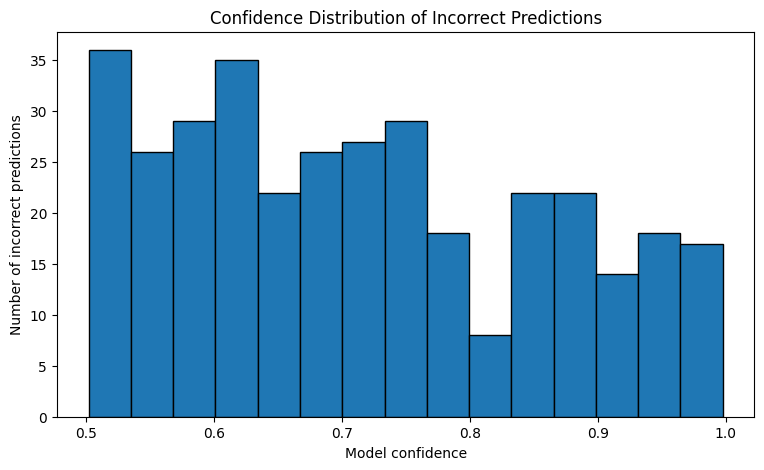

In [73]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.hist(
    errors_df["confidence"],
    bins=15,
    edgecolor="black"
)

plt.xlabel("Model confidence")
plt.ylabel("Number of incorrect predictions")
plt.title("Confidence Distribution of Incorrect Predictions")
plt.show()

In [74]:
import os

MODEL_DIR = "/content/BERT-Sentiment-Analysis/model"
TOKENIZER_DIR = "/content/BERT-Sentiment-Analysis/tokenizer"

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(TOKENIZER_DIR, exist_ok=True)

# Save best model weights
model.save_weights(
    os.path.join(MODEL_DIR, "best_bert_sentiment.weights.h5")
)

# Save BERT configuration
bert.config.save_pretrained(MODEL_DIR)

# Save tokenizer
tokenizer.save_pretrained(TOKENIZER_DIR)

print("Model weights, configuration and tokenizer saved!")

/usr/local/lib/python3.13/dist-packages/transformers/generation/tf_utils.py:465: UserWarning: `seed_generator` is deprecated and will be removed in a future version.
  warnings.warn("`seed_generator` is deprecated and will be removed in a future version.", UserWarning)


Model weights, configuration and tokenizer saved!


In [75]:
import shutil
import os

# Project directory
PROJECT_DIR = "/content/BERT-Sentiment-Analysis"

# Create ZIP archive
ZIP_PATH = shutil.make_archive(
    "/content/BERT-Sentiment-Analysis",
    "zip",
    root_dir=PROJECT_DIR
)

print("ZIP created successfully!")
print("File size:", round(os.path.getsize(ZIP_PATH) / (1024 * 1024), 2), "MB")

# Download ZIP
from google.colab import files
files.download(ZIP_PATH)

ZIP created successfully!
File size: 1093.94 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>